# GMM hyperparameter optimization

## 1 Setup and data

In [18]:
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
IMG_DIR = "figs/tuned"
MODEL_DIR = "model"
os.makedirs(IMG_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
pd.set_option("display.max_columns", None)

COLORS = ["#1d6c61", "#3e89ab", "#d08c3a", "#8a5aa3", "#5aa371", "#c4515a",
          "#5a6fa3", "#9aa83e", "#a37a5a", "#4fb3a3"]
plt.rcParams.update({"axes.grid": True, "grid.color": "#e6eeeb", "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=COLORS)})


def save(name):
    plt.tight_layout()
    plt.savefig(f"{IMG_DIR}/{name}", dpi=150, bbox_inches="tight")
    plt.show()

In [19]:
X = pd.read_csv("../data/H2_Cleaned_clustering.csv").to_numpy()
info = pd.read_csv("../data/H2_notdropped.csv")   # to describe clusters only
gmm_pca = joblib.load(f"{MODEL_DIR}/gmm_input_pca.joblib")   # the 11-component rotation saved by gmm.ipynb
Xg = gmm_pca.transform(X)
print("bookings:", len(X), " GMM input:", Xg.shape)

bookings: 48990  GMM input: (48990, 11)


The GMM runs on the 11 components, but the scores are computed on the 12 model columns

In [20]:
rng = np.random.default_rng(RANDOM_STATE)
S = np.sort(rng.choice(len(X), size=10_000, replace=False))   # the fixed silhouette sample


def evaluate(model):
    labels = model.predict(Xg)
    sizes = np.bincount(labels, minlength=model.n_components)
    proba = model.predict_proba(Xg).max(axis=1)
    return {"clusters": (sizes > 0).sum(),
            "smallest cluster %": sizes.min() / len(labels) * 100,
            "silhouette": silhouette_score(X[S], labels[S]),
            "davies_bouldin": davies_bouldin_score(X, labels),
            "calinski_harabasz": calinski_harabasz_score(X, labels),
            "certain %": (proba >= 0.999).mean() * 100}     # bookings assigned with probability >= 0.999

## 2 Baseline

In [21]:
baseline = joblib.load(f"{MODEL_DIR}/gmm_baseline.joblib")
baseline_scores = evaluate(baseline)
pd.DataFrame([baseline_scores], index=["baseline (5 components, full)"]).round(3)

,clusters,smallest cluster %,silhouette,davies_bouldin,calinski_harabasz,certain %
"baseline (5 components, full)",5,3.215,0.05,2.532,4028.045,99.992


## 3 Search space and optimization criteria

Search space
* `n_components`: 2 to 10
* `covariance_type`: `full` (any ellipse), `tied` (one ellipse shared by all clusters), `diag` (ellipses along the axes) and `spherical` (circles). The simpler shapes cannot stretch along a single whole-number value.
* `reg_covar`: 1e-6 (default), 1e-3, 1e-2, 1e-1. A floor added to every variance. Every column has a variance of about 1, so 0.01 to 0.1 stops a component from collapsing onto one value.

A configuration is valid only if:
* EM converged
* every cluster has at least 2% of the bookings

Criteria: silhouette (higher) and Davies–Bouldin (lower) are primary, Calinski–Harabasz (higher) is supporting. BIC, the GMM's own likelihood criterion, is not used for reasons I specified later

## 4 Grid search

In [22]:
rows = []
for n_components in range(2, 11):
    for covariance_type in ["full", "tied", "diag", "spherical"]:
        for reg_covar in [1e-6, 1e-3, 1e-2, 1e-1]:
            model = GaussianMixture(n_components=n_components, covariance_type=covariance_type, reg_covar=reg_covar,
                                    n_init=3, random_state=RANDOM_STATE).fit(Xg)
            rows.append({"n_components": n_components, "covariance_type": covariance_type, "reg_covar": reg_covar,
                         "converged": model.converged_, **evaluate(model), "BIC": model.bic(Xg)})

res = pd.DataFrame(rows)

## 5 Choosing the configuration

In [23]:
valid = res[res["converged"] & (res["smallest cluster %"] >= 2)].copy()
valid["mean_rank"] = (valid["silhouette"].rank(ascending=False) + valid["davies_bouldin"].rank()) / 2
valid = valid.sort_values(["mean_rank", "silhouette"], ascending=[True, False])   # ties: higher silhouette first
best = valid.iloc[0]
print("valid configurations:", len(valid), "of", len(res))
print("best:", int(best["n_components"]), "components,", best["covariance_type"], ", reg_covar", best["reg_covar"])
valid.head(10).round(3)

valid configurations: 119 of 144
best: 4 components, spherical , reg_covar 0.1


,n_components,covariance_type,reg_covar,converged,clusters,smallest cluster %,silhouette,davies_bouldin,calinski_harabasz,certain %,BIC,mean_rank
47,4,spherical,0.100,True,4,10.561,0.222,1.418,13057.631,20.900,949951.644,3.5
3,2,full,0.100,True,2,11.704,0.233,1.429,7975.660,58.896,674561.305,4.0
31,3,spherical,0.100,True,3,13.215,0.235,1.501,12443.308,35.234,1006432.676,7.5
11,2,diag,0.100,True,2,4.254,0.201,1.270,3290.031,74.136,684372.415,8.5
46,4,spherical,0.010,True,4,15.995,0.195,1.425,12494.786,43.266,911908.047,11.0
43,4,diag,0.100,True,4,10.237,0.213,1.460,11668.866,3.066,649713.946,11.5
63,5,spherical,0.100,True,5,10.345,0.209,1.473,11480.536,15.479,931352.559,12.5
45,4,spherical,0.001,True,4,17.206,0.188,1.442,12249.617,47.571,910835.177,16.0
44,4,spherical,0.000,True,4,17.240,0.188,1.443,12242.138,47.902,910825.531,17.0
30,3,spherical,0.010,True,3,19.320,0.218,1.585,12820.948,40.329,982441.782,17.5


* 119 of 144 configurations are valid
* 4 spherical components with `reg_covar` 0.1 have the best mean rank (silhouette 0.222, Davies–Bouldin 1.418). 2 full components come just behind, with a higher silhouette (0.233) but a worse Davies–Bouldin (1.429).
* The top 4 all use `reg_covar` 0.1, and spherical components take 7 of the top 10 places.

In [24]:
res.groupby("reg_covar")["certain %"].median().round(1)

reg_covar
0.000001    66.3
0.001000    47.4
0.010000    46.8
0.100000     4.2
Name: certain %, dtype: float64

Median share of bookings assigned with probability ≥ 0.999, per `reg_covar`: it falls from 66.3% at the default (1e-6) to 4.2% at 0.1. The floor on the variance removes the collapse seen in the baseline.

Why BIC is not used: the configurations with the lowest (best) BIC

In [25]:
res.sort_values("BIC").head(3).round(3)

,n_components,covariance_type,reg_covar,converged,clusters,smallest cluster %,silhouette,davies_bouldin,calinski_harabasz,certain %,BIC
128,10,full,0.0,True,10,1.166,-0.041,2.906,1489.423,88.318,-3027253.472
112,9,full,0.0,True,9,0.688,0.002,2.933,1859.552,88.108,-2972371.468
80,7,full,0.0,True,7,1.615,0.017,2.739,2587.794,100.000,-2748359.457


The best BIC goes to 10, 9 and 7 full components without regularisation. Their silhouettes are around 0 and up to 100% of their bookings are assigned with near-certainty. BIC rewards components that collapse onto exact whole-number values, so it would pick the worst clusterings.

## 6 Baseline vs tuned

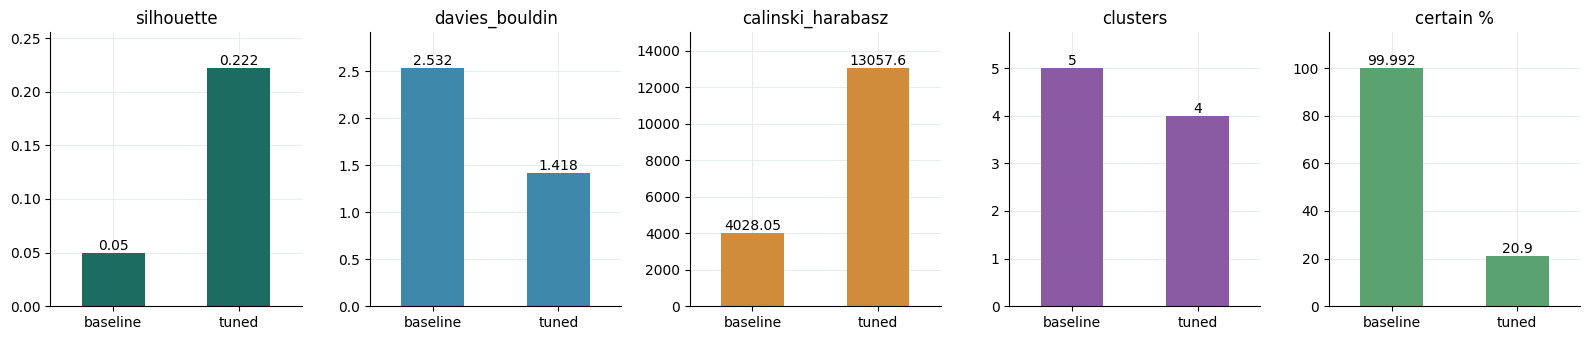

In [26]:
final = GaussianMixture(n_components=int(best["n_components"]), covariance_type=best["covariance_type"],
                        reg_covar=best["reg_covar"], n_init=3, random_state=RANDOM_STATE).fit(Xg)

order = np.argsort(-np.bincount(final.predict(Xg)))     # old cluster ids, largest first
final.weights_ = final.weights_[order]
final.means_ = final.means_[order]
final.covariances_ = final.covariances_[order]
final.precisions_ = final.precisions_[order]
final.precisions_cholesky_ = final.precisions_cholesky_[order]
labels = final.predict(Xg)
C = [f"C{k}" for k in range(final.n_components)]

comparison = pd.DataFrame([baseline_scores, evaluate(final)], index=["baseline", "tuned"]).round(3)
axes = comparison[["silhouette", "davies_bouldin", "calinski_harabasz", "clusters", "certain %"]].plot.bar(
    subplots=True, layout=(1, 5), figsize=(16, 3.5), legend=False, rot=0)
for ax in axes.flat:
    ax.bar_label(ax.containers[0])     # value above each bar
    ax.margins(y=0.15)
save("01_baseline_vs_tuned.png")

* The tuned model is better on silhouette, Davies–Bouldin and Calinski–Harabasz.
* Bookings assigned with near-certainty fall from 99.992% to 20.9%, so the probabilities now mean something

## 7 Tuned clusters

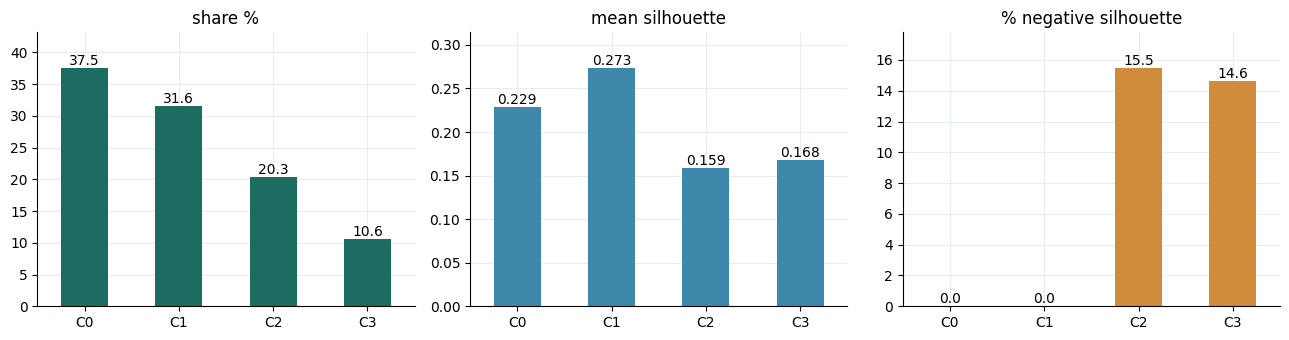

In [27]:
sil = silhouette_samples(X[S], labels[S])
per_cluster = pd.DataFrame({
    "share %": np.bincount(labels) / len(X) * 100,
    "mean silhouette": [sil[labels[S] == k].mean() for k in range(len(C))],
    "% negative silhouette": [(sil[labels[S] == k] < 0).mean() * 100 for k in range(len(C))],
}, index=C)

axes = per_cluster.plot.bar(subplots=True, layout=(1, 3), figsize=(13, 3.5), legend=False, rot=0)
for ax in axes.flat:
    fmt = "%.3f" if ax.get_title() == "mean silhouette" else "%.1f"
    ax.bar_label(ax.containers[0], fmt=fmt)     # value above each bar
    ax.margins(y=0.15)
save("02_sizes_silhouette.png")

In [28]:
g = info.groupby(labels)
prof = pd.DataFrame({
    "lead time (median days)": g["LeadTime"].median(),
    "nights (median)": g["TotalNights"].median(),
    "guests (mean)": g["TotalGuests"].mean(),
    "ADR (median)": g["ADR"].median(),
    "special requests (mean)": g["TotalOfSpecialRequests"].mean(),
    "repeat guests %": g["IsRepeatedGuest"].mean() * 100,
})
prof.index = C
prof.round(1)

,lead time (median days),nights (median),guests (mean),ADR (median),special requests (mean),repeat guests %
C0,68.0,3.0,2.1,108.0,1.4,0.4
C1,75.0,3.0,1.9,96.3,0.0,0.5
C2,3.0,1.0,1.5,96.0,0.5,11.7
C3,54.0,3.0,3.3,177.5,0.8,0.2


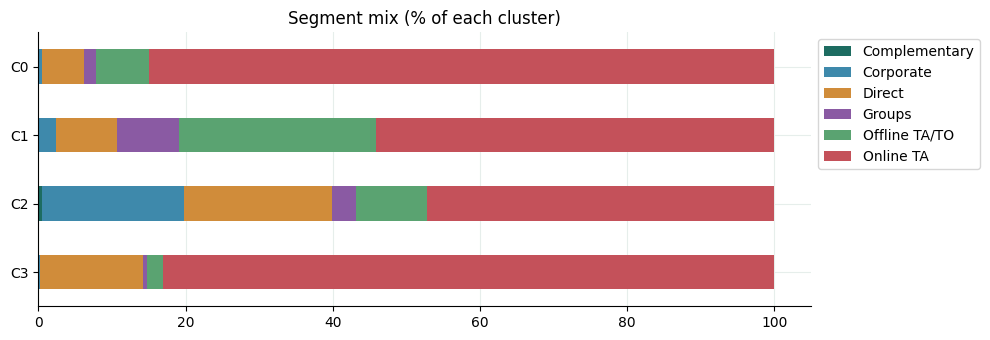

In [29]:
mix = pd.crosstab(labels, info["Segment"], normalize="index") * 100
mix.index = C
mix.plot.barh(stacked=True, figsize=(10, 3.5), title="Segment mix (% of each cluster)")
plt.gca().invert_yaxis()
plt.legend(bbox_to_anchor=(1, 1))
save("03_segment_mix.png")

## 8 PCA view

variance explained by PC1 + PC2: 0.575


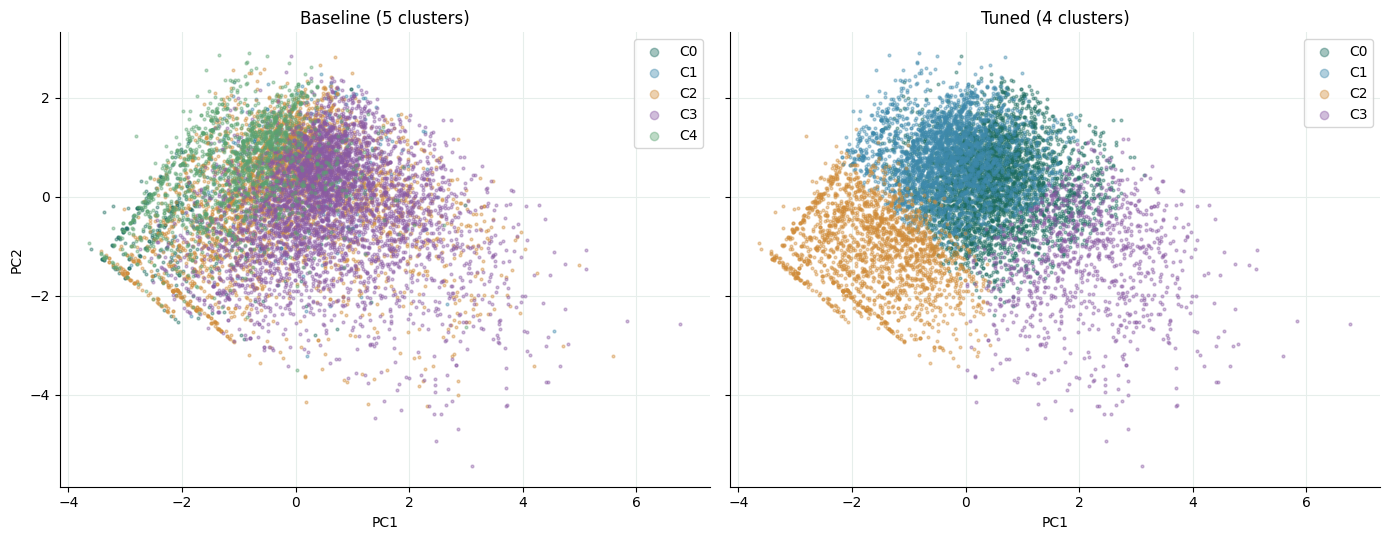

In [30]:
pca = PCA(n_components=2).fit(X)
P = pca.transform(X[S])
print("variance explained by PC1 + PC2:", round(pca.explained_variance_ratio_.sum(), 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for ax, model_labels, title in [(axes[0], baseline.predict(Xg), "Baseline"), (axes[1], labels, "Tuned")]:
    lab = model_labels[S]
    for k in range(model_labels.max() + 1):
        ax.scatter(P[lab == k, 0], P[lab == k, 1], s=4, alpha=0.4, color=COLORS[k], label=f"C{k}")
    ax.set_title(f"{title} ({model_labels.max() + 1} clusters)")
    ax.set_xlabel("PC1")
    ax.legend(markerscale=3)
axes[0].set_ylabel("PC2")
save("04_pca_baseline_vs_tuned.png")

The baseline's clusters overlap completely in the PCA plane. The tuned clusters take separate regions: C2 at the bottom left, C3 to the right, and C0 and C1 in the middle, where they overlap because they differ mainly in special requests 

## 9 How the clusters differ from the average booking

Effect size = (cluster mean − overall mean) / overall standard deviation. Positive is above average

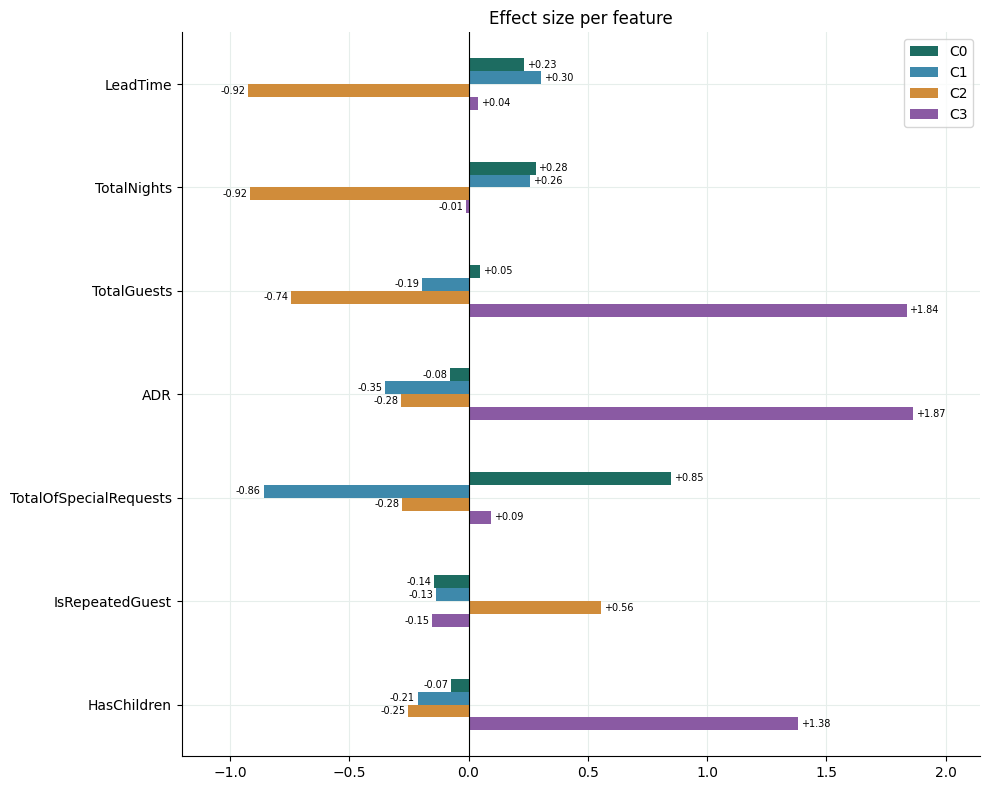

In [31]:
desc = info.copy()
desc["HasChildren"] = ((desc["Children"] + desc["Babies"]) > 0).astype(int)
feats = desc[["LeadTime", "TotalNights", "TotalGuests", "ADR", "TotalOfSpecialRequests", "IsRepeatedGuest", "HasChildren"]]

effect = (feats.groupby(labels).mean() - feats.mean()) / feats.std()
effect.index = C
ax = effect.T.plot.barh(figsize=(10, 8), title="Effect size per feature")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%+.2f", fontsize=7, padding=2)   # value at the end of each bar
ax.margins(x=0.1)                                            # room for the labels
plt.axvline(0, color="black", lw=0.8)
plt.gca().invert_yaxis()
save("05_effect_sizes.png")

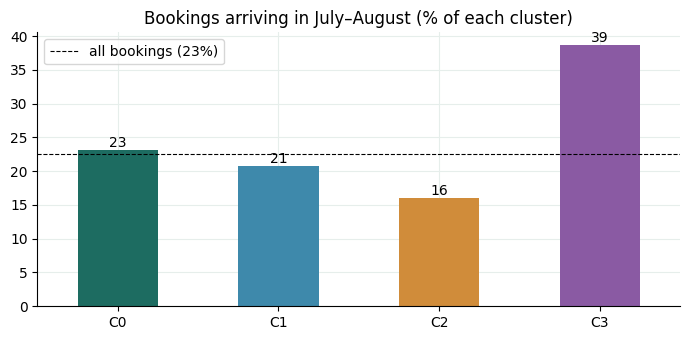

In [32]:
summer = desc["ArrivalDateMonth"].isin(["July", "August"])
share = summer.groupby(labels).mean() * 100
share.index = C

ax = share.plot.bar(figsize=(7, 3.5), rot=0, color=COLORS[:len(C)], title="Bookings arriving in July–August (% of each cluster)")
ax.bar_label(ax.containers[0], fmt="%.0f")     # value above each bar
ax.axhline(summer.mean() * 100, color="black", ls="--", lw=0.8, label=f"all bookings ({summer.mean() * 100:.0f}%)")
ax.legend(handles=ax.lines)     # only the dashed line
save("06_summer_share.png")

| Cluster | Share | Name | Main traits |
|---|---|---|---|
| C0 | 37.5% | Plan ahead guests | 1.4 special requests, otherwise average: 68 days ahead, 3 nights, 2.1 guests, €108, mostly Online TA |
| C1 | 31.6% | Very plain agency bookings | no special requests, the longest lead time (75 days), a lower price (€96), the most Offline TA/TO |
| C2 | 20.3% | Last minute short stays | 3 days ahead, 1 night, 1.5 guests, the most repeat guests (11.7%), the most Corporate and Direct |
| C3 | 10.6% | Large parties | 3.3 guests, the highest price (€178), by far the most children |

* Children and arrival month were not used to build the clusters, but they still fit: C3 has by far the most children and the most July–August arrivals (39%, against 23% for all bookings), C2 the fewest (16%).

## 10 Leakage audit

`IsCanceled` was not an input and was not used to choose any hyperparameter. It is only looked at here, to check that the clusters are not just a split into "cancels" and "does not cancel" 

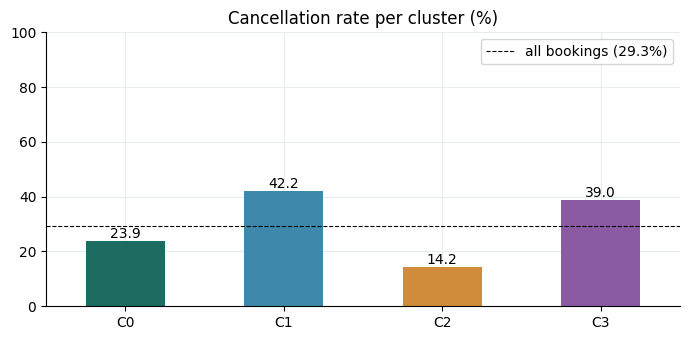

In [33]:
rate = info.groupby(labels)["IsCanceled"].mean() * 100
rate.index = C
overall = info["IsCanceled"].mean() * 100

ax = rate.plot.bar(figsize=(7, 3.5), rot=0, color=COLORS[:len(C)], title="Cancellation rate per cluster (%)")
ax.bar_label(ax.containers[0], fmt="%.1f")     # value above each bar
ax.axhline(overall, color="black", ls="--", lw=0.8, label=f"all bookings ({overall:.1f}%)")
ax.set_ylim(0, 100)
ax.legend(handles=ax.lines)     # only the dashed line
save("07_cancellation.png")

Cancellation ranges from 14.2% (C2) to 42.2% (C1), around 29.3% for all bookings. No cluster is close to 0% or 100%, so the clusters are not a disguised cancellation split and nothing leaked into the inputs.

## Save the tuned model

In [34]:
joblib.dump(final, f"{MODEL_DIR}/gmm_tuned.joblib")

['model/gmm_tuned.joblib']